# Exploring Mistral Reasoning Modes

Reasoning is a model's capability to leverage extra compute and chains of thought to explore a problem before confidently providing a final answer. Models without reasoning usually reply directly with a single text string. With reasoning, the model instead produces a chain of thought.

**The response content is a list of interleaved blocks - reasoning segments and text, possibly alongside tool calls - whose length grows with the configured verbosity or reasoning effort level.**


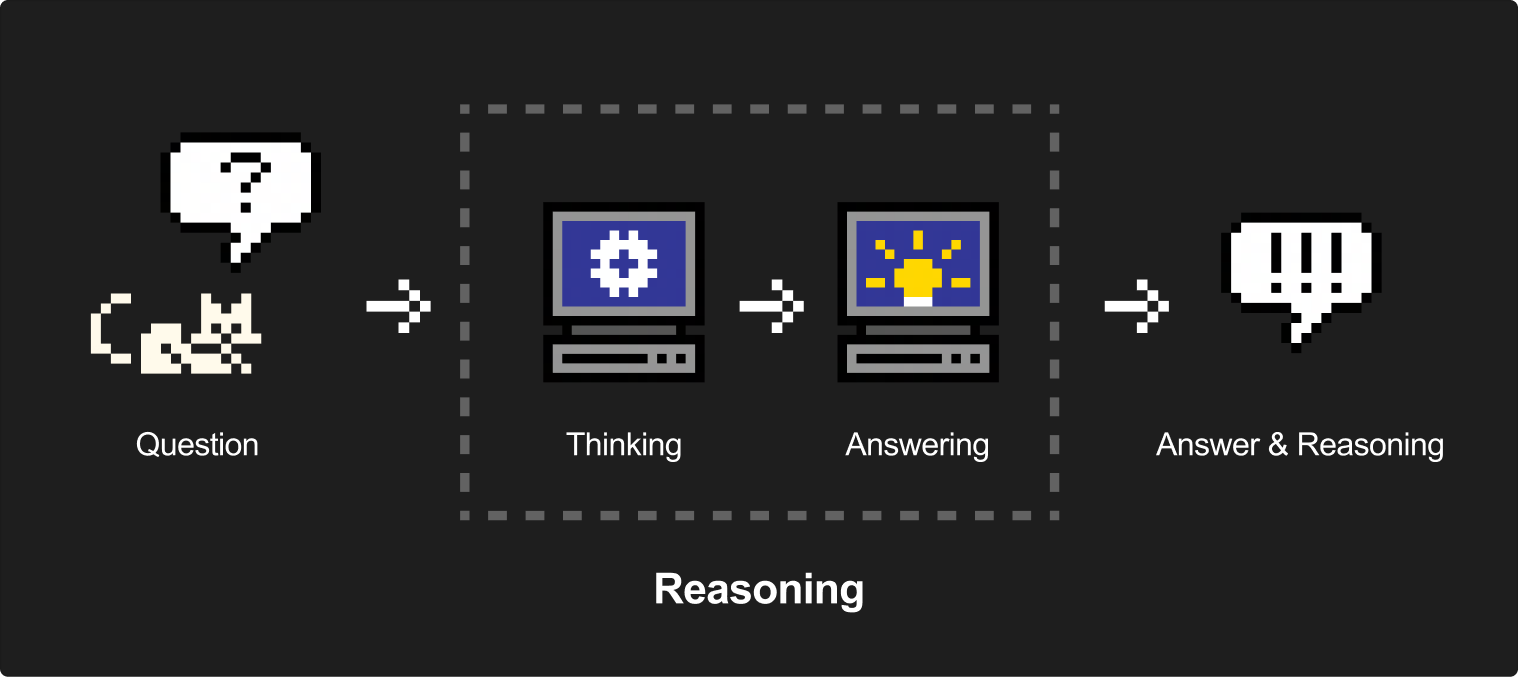

This lets the model refine its answer as it goes, and only commit to a final reply once it reaches sufficient confidence.

## Reasoning Efforts

Different models expose different reasoning effort levels, from toggling reasoning on or off to controlling how verbose the reasoning is.

Because a reasoning response is a list of interleaved content blocks rather than a single string, handling it requires a slightly different implementation than for previous non-reasoning models - and you should expect the number of blocks to vary with the reasoning effort.

In this cookbook we explore these reasoning effort modes and their accuracy, cost efficiency, and latency.

## Install

First, we install the `mistralai` SDK and set up a `MISTRAL_API_KEY`, which you can create in [Mistral Studio](https://console.mistral.ai/api-keys).


In [1]:
!pip install mistralai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 11.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [mistralai]


In [2]:
from mistralai.client import Mistral
import getpass
import os

if not os.environ.get("MISTRAL_API_KEY"):
    os.environ["MISTRAL_API_KEY"] = getpass.getpass("Mistral API key: ")

client = Mistral(os.environ["MISTRAL_API_KEY"], timeout_ms=1000*60*20)

Mistral API key: ··········


## Calling a model

With the client ready, here is a first call to the model on a simple math problem.

### No Reasoning
When using a non-reasoning model, the expected response is a single string or tool calls.


In [3]:
model = "ministral-14b-2512"

messages = [
    {
        "role": "user",
        "content": "Solve the following equation: a^3 + a^2 = 36"
    }
]

chat_response = client.chat.complete(
    model=model,
    messages=messages
)

print(chat_response.choices[0].message.content)

### Understanding the Equation

The given equation is:
\[ a^3 + a^2 = 36 \]

First, I recognize that this is a cubic equation because the highest power of \( a \) is 3. My goal is to find all real (and possibly complex) roots of this equation.

### Rewriting the Equation

To make it easier to solve, I think it's best to rewrite the equation in standard form:
\[ a^3 + a^2 - 36 = 0 \]

Now, it's a standard cubic equation:
\[ f(a) = a^3 + a^2 - 36 = 0 \]

### Attempting to Factor the Equation

For cubic equations, factoring can be a good first step. I recall the Rational Root Theorem, which suggests that any possible rational root, \( p/q \), of the polynomial equation \( a^n + \ldots + k = 0 \) must have \( p \) as a factor of the constant term and \( q \) as a factor of the leading coefficient.

In this case:
- Constant term: \(-36\)
- Leading coefficient: \(1\)

Possible rational roots are \( \pm1, \pm2, \pm3, \pm4, \pm6, \pm9, \pm12, \pm18, \pm36 \).

### Testing Potential Roots

Let'

You receive a single strong block with the answer of the model.
### Reasoning
With reasoning models, you will receive at least one reasoning block before receiving an answer, let's try Le Chonk, AKA Mistral Large 4, with the lowest reasoning effort level.

In [4]:
model = "mistral-large-4"

messages = [
    {
        "role": "user",
        "content": "Solve the following equation: a^3 + a^2 = 36"
    }
]

chat_response = client.chat.complete(
    model=model,
    messages=messages,
    reasoning_effort="low"
)

In [5]:
answer = chat_response.choices[0].message
if isinstance(answer.content, str):
    print(answer.content)
else:
    for part in answer.content:
        if part.type == "text":
            print("\n\n-----ANSWER------\n\n")
            print(part.text)
        else:
            print("\n\n----REASONING----\n\n")
            for chunk in part.thinking:
                print(chunk.text)



----REASONING----


The user wants me to solve the equation $a^3 + a^2 = 36$.

 This is a cubic equation. I can rearrange it to standard form:
 $a^3 + a^2 - 36 = 0$

 I should try to find rational roots using the Rational Root Theorem. Possible rational roots are factors of 36: $\pm 1, \pm 2, \pm 3, \pm 4, \pm 6, \pm 9, \pm 12, \pm 18, \pm 36$.

 Let me test $a = 3$:
 $3^3 + 3^2 - 36 = 27 + 9 - 36 = 36 - 36 = 0$.
 So $a = 3$ is a root.

 Now I can factor out $(a - 3)$ using polynomial division or synthetic division.

 Using synthetic division with root 3:
 Coefficients: 1 (for $a^3$), 1 (for $a^2$), 0 (for $a$), -36 (constant)

 3 | 1   1   0   -36
   |     3   12    36
   ----------------
     1   4   12     0

 So the quotient is $a^2 + 4a + 12 = 0$.

 Now solve $a^2 + 4a + 12 = 0$ using the quadratic formula:
 $a = \frac{-4 \pm \sqrt{16 - 48}}{2} = \frac{-4 \pm \sqrt{-32}}{2} = \frac{-4 \pm 4i\sqrt{2}}{2} = -2 \pm 2i\sqrt{2}$.

 So the solutions are:
 $a = 3$
 $a = -2 + 2i\sqrt{2}

## Reasoning modes

Our most powerful models can switch between reasoning modes. Reasoning is the ability of a model to produce and follow a chain of thought before giving its final response - this extra token usage lets the model explore the question and refine its answer.

Among our first-party and third-party reasoning models:

- **Mistral Large 4**
  - `reasoning_effort="low"`: minimal reasoning - the model thinks briefly before replying.
  - `reasoning_effort="medium"`: a balanced effort - the model reasons for a dedicated amount before replying.
  - `reasoning_effort="high"` *(default)*: high verbose mode - the model reasons at length before replying.
- **Mistral Medium 3.5**
  - `reasoning_effort="none"` *(default)*: no reasoning - the model replies directly.
  - `reasoning_effort="high"`: high verbose mode - the model reasons at length before replying.
- **ZAI GLM 5.3**
  - `reasoning_effort="low"` *(default)*: minimal reasoning - the model thinks briefly before replying.
  - `reasoning_effort="high"`: a high reasoning effort - the model reasons for a large amount before replying.
  - `reasoning_effort="max"`: high verbose mode - the model reasons at length before replying.


## Benchmarking Reasoning Models

To compare reasoning modes beyond a single example, we benchmark each model and effort level on [GPQA Diamond](https://huggingface.co/datasets/fingertap/GPQA-Diamond), a set of graduate-level multiple-choice questions where reasoning tends to pay off. For every question we record the predicted answer, correctness, and token usage. Completed runs are cached on disk, so re-running the notebook only executes new configurations.


In [6]:
MODEL_EFFORTS = {
    "mistral-large-4": ["low", "medium", "high"],
    "mistral-medium-3.5": ["none", "high"],
    "zai-glm-5-3": ["low", "high", "max"],
}

In [ ]:
# Cached benchmark results
!wget -q https://raw.githubusercontent.com/mistralai/cookbook/main/mistral/reasoning/gpqa_diamond_results.json

In [7]:
#@title Run GPQA Benchmark
import json
import hashlib
import os
import random
import re
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm
import time

from datasets import load_dataset

SEED = 42
LETTERS = "ABCD"
CACHE_FILE = "gpqa_diamond_results.json"
N_WORKERS = 4
TRIES = 10

SYS_PROMPT = "You are a helpful assistant, reason before answering."
USER_TEMPLATE = """Answer the following multiple choice question. Once you have a response, your final answer after any reasoning should be in the following format: 'ANSWER: $LETTER' (without quotes) where LETTER is one of {letters}.

{question}"""


def build_prompt(example) -> str:
    return USER_TEMPLATE.format(letters=", ".join(LETTERS), question=example["question"])


def parse_answer(text: str) -> str | None:
    """GPQA-Diamond scoring: look for 'ANSWER: X', then 'The answer is (X)', then a bare trailing letter."""
    m = re.search(r"ANSWER:\s*\(?([A-D])\)?", text, re.IGNORECASE)
    if m:
        return m.group(1).upper()
    m = re.search(r"[Tt]he answer is:?\s*\(?([A-D])\)?", text)
    if m:
        return m.group(1).upper()
    m = re.findall(r"\(?([A-D])\)?", text.strip()[-10:])
    return None


def ask_question(model, effort, ex):
    """Make one API call and return a per-sample record (thread-safe: no shared state)."""
    gold = ex["answer"]
    record = {
        "model": model, "effort": effort, "gold": gold,
        "pred": None, "correct": False, "parse_fail": False,
        "completion_tokens": None, "reasoning_tokens": None,
        "prompt_tokens": None, "content": None, "error": None,
    }
    for tr in range(TRIES):
        try:
            response = client.chat.complete(
                model=model,
                messages=[
                    {"role": "system", "content": SYS_PROMPT},
                    {"role": "user", "content": build_prompt(ex)},
                ],
                reasoning_effort=effort,
            )
            content = (response.choices[0].message.content if isinstance(response.choices[0].message.content, str)
                      else response.choices[0].message.content[-1].text)
            record["content"] = content

            usage = getattr(response, "usage", None)
            if usage is not None:
                record["prompt_tokens"] = getattr(usage, "prompt_tokens", None)
                record["completion_tokens"] = getattr(usage, "completion_tokens", None)
                record["reasoning_tokens"] = getattr(usage, "reasoning_tokens", None)
                if record["prompt_tokens"] is None and isinstance(usage, dict):
                    record["prompt_tokens"] = usage.get("prompt_tokens")
                    record["completion_tokens"] = usage.get("completion_tokens")
                    record["reasoning_tokens"] = usage.get("reasoning_tokens")

            pred = parse_answer(content)
            record["pred"] = pred
            record["correct"] = pred == gold
            record["parse_fail"] = pred is None
            break
        except Exception as e:
            record["error"] = str(e)
            print(e)
            time.sleep(2*(tr+1))
    return record

# ---------- cache handling ----------
def run_id(model, effort, dataset_id, n_samples):
    """Stable key for a run: same settings -> same key."""
    raw = json.dumps({"model": model, "effort": effort,
                      "dataset": dataset_id, "n": n_samples,
                      "prompt": USER_TEMPLATE})
    return hashlib.md5(raw.encode()).hexdigest()[:12]

def load_cache():
    if os.path.exists(CACHE_FILE):
        try:
            with open(CACHE_FILE) as f:
                return json.load(f)
        except (json.JSONDecodeError, OSError):
            print("Warning: cache file unreadable, starting fresh.")
    return {}

def save_cache(cache):
    with open(CACHE_FILE, "w") as f:
        json.dump(cache, f, indent=2)

cache = load_cache()

DATASET_ID = "fingertap/GPQA-Diamond"
ds = load_dataset(DATASET_ID, split="test")
N_SAMPLES = len(ds)
sample = list(range(N_SAMPLES))

results = {}
per_sample = []

for model, efforts in MODEL_EFFORTS.items():
    for effort in efforts:
        key = (model, effort)
        rid = run_id(model, effort, DATASET_ID, N_SAMPLES)

        # --- reuse cached run if available and complete ---
        if rid in cache and cache[rid].get("total") == N_SAMPLES:
            r = cache[rid]
            results[key] = r
            print(f">>> {model} (effort={effort}): reusing cached run "
                  f"({r['correct']}/{r['total']} = "
                  f"{100 * r['correct'] / r['total']:.1f}%)")
            continue

        # --- run the eval with N_WORKERS parallel requests ---
        agg = {
            "model": model, "effort": effort,
            "correct": 0, "total": 0, "parse_fail": 0,
            "completion_tokens": [], "reasoning_tokens": [],
            "prompt_tokens": [],
        }
        records = {}

        with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
            futures = {
                pool.submit(ask_question, model, effort, ds[idx]): i
                for i, idx in enumerate(sample, 1)
            }
            for future in tqdm(as_completed(futures), total=N_SAMPLES,
                               desc=f"{model} | effort={effort}"):
                i = futures[future]
                record = future.result()
                records[i] = record

        for i in sorted(records):
            record = records[i]
            agg["total"] += 1
            agg["correct"] += record["correct"]
            agg["parse_fail"] += record["parse_fail"]
            if record["error"]:
                print(f"  API error on Q{i}: {record['error']}")
            for tok in ("completion_tokens", "reasoning_tokens", "prompt_tokens"):
                if record[tok] is not None:
                    agg[tok].append(record[tok])

            per_sample.append({"q_idx": sample[i - 1], **record})

            print(f"[{i:3d}/{N_SAMPLES}] gold={record['gold']} pred={record['pred']} "
                  f"tok={record['completion_tokens']} reason={record['reasoning_tokens']} "
                  f"{'OK' if record['correct'] else 'WRONG'}")

        results[key] = agg

        if agg["total"] == N_SAMPLES:
            cache[rid] = agg
            save_cache(cache)
            print(f">>> {model} (effort={effort}): "
                  f"{agg['correct']}/{N_SAMPLES} = "
                  f"{100 * agg['correct'] / N_SAMPLES:.1f}% (cached)")

print("\n===== RESULTS =====")
print(f"Dataset: {DATASET_ID}, full set: {N_SAMPLES} questions")
hdr = (f"{'Model':<22} {'Effort':<8} {'Accuracy':<16} "
       f"{'Avg out tok':<12} {'Avg reason tok':<14} Parse fails")
print(hdr)
for (model, effort), r in sorted(results.items()):
    c, t = r["correct"], r["total"]
    avg_out = (sum(r["completion_tokens"]) / len(r["completion_tokens"])
               if r["completion_tokens"] else float("nan"))
    avg_rea = (sum(r["reasoning_tokens"]) / len(r["reasoning_tokens"])
               if r["reasoning_tokens"] else float("nan"))
    print(f"{model:<22} {effort:<8} {c}/{t} = {100 * c / t:5.1f}%   "
          f"{avg_out:<12.1f} {avg_rea:<14.1f} {r['parse_fail']}")

test/gpqa_diamond.parquet: reconstructing file:   0%|          |  0.00B / 71.8kB            

test/gpqa_diamond.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/198 [00:00<?, ? examples/s]

>>> mistral-large-4 (effort=low): reusing cached run (173/198 = 87.4%)
>>> mistral-large-4 (effort=medium): reusing cached run (178/198 = 89.9%)
>>> mistral-large-4 (effort=high): reusing cached run (181/198 = 91.4%)
>>> mistral-medium-3.5 (effort=none): reusing cached run (118/198 = 59.6%)
>>> mistral-medium-3.5 (effort=high): reusing cached run (147/198 = 74.2%)
>>> zai-glm-5-3 (effort=low): reusing cached run (143/198 = 72.2%)
>>> zai-glm-5-3 (effort=high): reusing cached run (175/198 = 88.4%)
>>> zai-glm-5-3 (effort=max): reusing cached run (180/198 = 90.9%)

===== RESULTS =====
Dataset: fingertap/GPQA-Diamond, full set: 198 questions
Model                  Effort   Accuracy         Avg out tok  Avg reason tok Parse fails
mistral-large-4        high     181/198 =  91.4%   16940.8      nan            0
mistral-large-4        low      173/198 =  87.4%   6555.1       nan            0
mistral-large-4        medium   178/198 =  89.9%   11420.3      nan            0
mistral-medium-3.5   

Let's plot accuracy vs. cost for this benchmark: the higher the accuracy and the lower the cost, the better the model + reasoning effort combination for the use case.

In [8]:
PRICING = {
    "mistral-large-4": {"input": 0.7, "output": 2.1},
    "mistral-medium-3.5": {"input": 1.5, "output": 7.5},
    "zai-glm-5-3": {"input": 1.4, "output": 4.4},
}

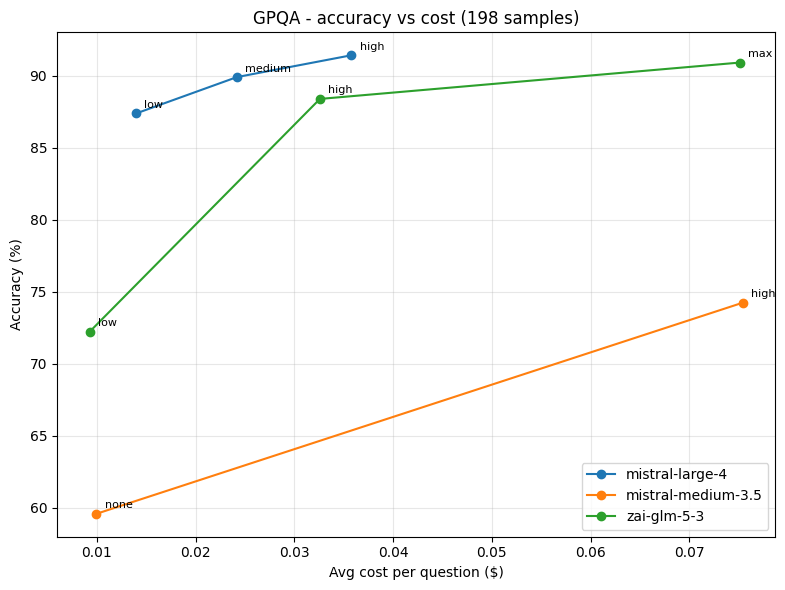

In [9]:
#@title Plot Accuracy vs Cost

import matplotlib.pyplot as plt

DEFAULT_PRICING = {"input": 0, "output": 0}

plot_data = {}
for (model, effort), r in results.items():
    pricing = PRICING.get(model, DEFAULT_PRICING)
    out_tokens = r["completion_tokens"] or []
    in_tokens = r.get("prompt_tokens") or []
    if not out_tokens:
        continue
    avg_out = sum(out_tokens) / len(out_tokens)
    avg_in = sum(in_tokens) / len(in_tokens) if in_tokens else 0.0
    avg_cost = (avg_in * pricing["input"] + avg_out * pricing["output"]) / 1e6
    acc = 100 * r["correct"] / r["total"]
    plot_data.setdefault(model, []).append((effort, avg_cost, acc))

effort_order = ["none", "low", "medium", "high", "max"]

plt.figure(figsize=(8, 6))

for model, points in plot_data.items():
    points = sorted(points, key=lambda p: effort_order.index(p[0])
                    if p[0] in effort_order else 99)
    xs = [p[1] for p in points]
    ys = [p[2] for p in points]

    plt.plot(xs, ys, marker="o", label=model)

    for effort, x, y in points:
        plt.annotate(effort, (x, y), textcoords="offset points",
                     xytext=(6, 4), fontsize=8)

plt.xlabel("Avg cost per question ($)")
plt.ylabel("Accuracy (%)")
plt.title(f"GPQA - accuracy vs cost ({N_SAMPLES} samples)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Large 4 achieved the best score with `high`, while staying considerably cheaper than the second-best. Le Chonk sits on the Pareto frontier of performance vs. cost among the selected models.

## Digging into Mistral Large 4's strengths and weaknesses

For the rest of this cookbook we focus on `mistral-large-4` and its three reasoning modes. We send each mode four themes of questions - casual small talk, simple queries, math, and long-form generation - and measure latency (time to first answer token and total) alongside token usage.


In [10]:
questions = {
    # Theme 1: Casual questions (greetings, small talk)
    "casual": [
        "Hi there!",
        "How are ya?",
        "What's up?",
        "Good morning, how's your day going?",
        "Hey, how's it going?",
        "Nice weather today, isn't it?",
        "How was your weekend?",
        "Long time no see, how have you been?",
        "What have you been up to lately?",
        "Hey, got a minute to chat?",
    ],

    # Theme 2: Simple queries (quick practical requests)
    "simple_queries": [
        "Translate this sentence to French: I love pizza.",
        "Fix any spelling mistake in this sentence: I recieved your email yestreday.",
        "Summarize this in one sentence: The meeting was postponed because the client was sick.",
        "Rewrite this more politely: Send me the report now.",
        "Check the grammar in: He don't like apples.",
        "What's a synonym for 'happy'?",
        "Convert 5 kilometers to miles.",
        "Give me a shorter version of: We will attend the event that takes place next week.",
        "Capitalize and punctuate this: the quick brown fox jumps over the lazy dog",
        "Translate 'good evening' to Spanish.",
    ],

    # Theme 3: Math questions
    "math": [
        "Compute the smallest positive integer x such that 7^x ≡ 1 (mod 360).",
        "Solve for x: log₂(x) + log₂(x − 6) = 4.",
        "Evaluate the integral of x·e^(−x²) dx from 0 to ∞.",
        "Find all real solutions of the system: x² + y² = 25, x + y = 7.",
        "Compute the sum of the infinite series: 1/2 + 1/6 + 1/24 + ... (n!/(n+1)! terms).",
        "What is the coefficient of x⁵ in the expansion of (2x − 3)⁸?",
        "A bag has 5 red and 7 blue balls. Two are drawn without replacement. What is the probability they are different colors?",
        "Solve the differential equation y' = 3x²·y with y(0) = 2, and give y(1).",
        "Compute lim(x→0) of (e^(3x) − 1 − 3x) / x².",
        "Find the eigenvalues of the matrix [[4, 1], [2, 3]].",
    ],

    # Theme 4: Long queries (generative, open-ended requests)
    "long_queries": [
        "Write me a story of a young sailor who discovers a hidden island in the Pacific.",
        "Make an article about the impact of artificial intelligence on modern healthcare.",
        "Write a detailed essay explaining why the Roman Empire fell.",
        "Compose a short story about a detective solving a mystery in a small coastal town.",
        "Write me a blog post about the benefits of remote work for software developers.",
        "Draft a speech about the importance of environmental conservation for high school students.",
        "Write an article covering the history and evolution of video game consoles.",
        "Create a story about two strangers who meet during a snowstorm and become friends.",
        "Make a comprehensive guide about starting a small organic vegetable garden.",
        "Write a review-style article about how electric cars are changing the automotive industry.",
    ],
}

In [11]:
#@title Run Latency Evals
import time
import pandas as pd

MODEL = "mistral-large-4"
efforts = ["low", "medium", "high"]
# N_RUNS = 5
N_RUNS = 1

MAX_RETRIES = 3
BACKOFF_BASE = 2.0

def has_answer_text(content):
    """True when delta.content carries final-answer text (no reasoning)."""
    if isinstance(content, str):
        return bool(content)
    return False

def stream_with_retries(model, question, effort):
    """Run one streamed request with retries on transient errors.

    Returns (ttfat, usage, total_latency) or raises on final failure.
    """
    last_error = None

    for attempt in range(1, MAX_RETRIES + 1):
        try:
            start = time.perf_counter()
            ttfat = None
            usage = None

            stream = client.chat.stream(
                model=model,
                messages=[{"role": "user", "content": question}],
                reasoning_effort=effort,
            )

            for event in stream:
                now = time.perf_counter()
                data = event.data

                if ttfat is None and data.choices and has_answer_text(data.choices[0].delta.content):
                    ttfat = now - start

                if data.usage:
                    usage = data.usage

            if usage is None:
                raise RuntimeError("stream finished without usage data")

            return ttfat, usage, time.perf_counter() - start

        except KeyboardInterrupt:
            raise
        except Exception as err:
            last_error = err
            if attempt < MAX_RETRIES:
                wait = BACKOFF_BASE ** attempt
                print(f"  [attempt {attempt}/{MAX_RETRIES} failed: {type(err).__name__}: {err}] "
                      f"retrying in {wait:.0f}s...")
                time.sleep(wait)

    raise RuntimeError(f"failed after {MAX_RETRIES} attempts: {last_error}")


records = []
failed = []

for run in range(1, N_RUNS + 1):
    for effort in efforts:
        for theme, theme_questions in questions.items():
            for question in theme_questions:
                try:
                    ttfat, usage, total_latency = stream_with_retries(MODEL, question, effort)
                except Exception as err:
                    print(f"[run {run}/{N_RUNS} | {effort:>6}/{theme}] FAILED: {err}")
                    failed.append({
                        "run": run, "effort": effort, "theme": theme,
                        "question": question, "error": str(err),
                    })
                    continue

                completion_tokens = usage.completion_tokens
                reasoning_tokens = usage.completion_tokens_details["reasoning_tokens"]

                records.append({
                    "run": run,
                    "effort": effort,
                    "theme": theme,
                    "question": question,
                    "prompt_tokens": usage.prompt_tokens,
                    "completion_tokens": completion_tokens,
                    "reasoning_tokens": reasoning_tokens,
                    "answer_tokens": completion_tokens - reasoning_tokens,
                    "ttfat_s": round(ttfat, 3),
                    "total_latency_s": round(total_latency, 3),
                })

                print(f"[run {run}/{N_RUNS} | {effort:>6}/{theme}] "
                      f"ttft={ttfat:.2f}s total={total_latency:.2f}s "
                      f"completion={completion_tokens} reasoning={reasoning_tokens}")

df = pd.DataFrame(records)
df.to_csv("mistral_benchmark.csv", index=False)

if failed:
    pd.DataFrame(failed).to_csv("mistral_benchmark_errors.csv", index=False)
    print(f"\n{len(failed)} request(s) failed permanently — see mistral_benchmark_errors.csv")

df.head(10)

[run 1/5 |    low/casual] ttft=1.07s total=1.16s completion=71 reasoning=56
[run 1/5 |    low/casual] ttft=1.87s total=1.94s completion=115 reasoning=97
[run 1/5 |    low/casual] ttft=0.97s total=1.07s completion=62 reasoning=41
[run 1/5 |    low/casual] ttft=1.58s total=1.98s completion=121 reasoning=93
[run 1/5 |    low/casual] ttft=1.24s total=1.39s completion=97 reasoning=71
[run 1/5 |    low/casual] ttft=18.81s total=26.47s completion=163 reasoning=129
[run 1/5 |    low/casual] ttft=1.49s total=1.73s completion=118 reasoning=79
[run 1/5 |    low/casual] ttft=2.64s total=2.65s completion=178 reasoning=150
[run 1/5 |    low/casual] ttft=3.37s total=8.19s completion=165 reasoning=135
[run 1/5 |    low/casual] ttft=1.07s total=1.09s completion=74 reasoning=58
[run 1/5 |    low/simple_queries] ttft=2.89s total=2.89s completion=120 reasoning=112
[run 1/5 |    low/simple_queries] ttft=1.27s total=1.30s completion=76 reasoning=67
[run 1/5 |    low/simple_queries] ttft=9.09s total=10.39s c

,run,effort,theme,question,prompt_tokens,completion_tokens,reasoning_tokens,answer_tokens,ttfat_s,total_latency_s
0,1,low,casual,Hi there!,18,71,56,15,1.074,1.157
1,1,low,casual,How are ya?,19,115,97,18,1.872,1.940
2,1,low,casual,What's up?,19,62,41,21,0.973,1.072
3,1,low,casual,"Good morning, how's your day going?",24,121,93,28,1.577,1.978
4,1,low,casual,"Hey, how's it going?",22,97,71,26,1.236,1.390
5,1,low,casual,"Nice weather today, isn't it?",23,163,129,34,18.812,26.466
6,1,low,casual,How was your weekend?,20,118,79,39,1.485,1.733
7,1,low,casual,"Long time no see, how have you been?",25,178,150,28,2.639,2.649
8,1,low,casual,What have you been up to lately?,23,165,135,30,3.371,8.187
9,1,low,casual,"Hey, got a minute to chat?",23,74,58,16,1.070,1.088


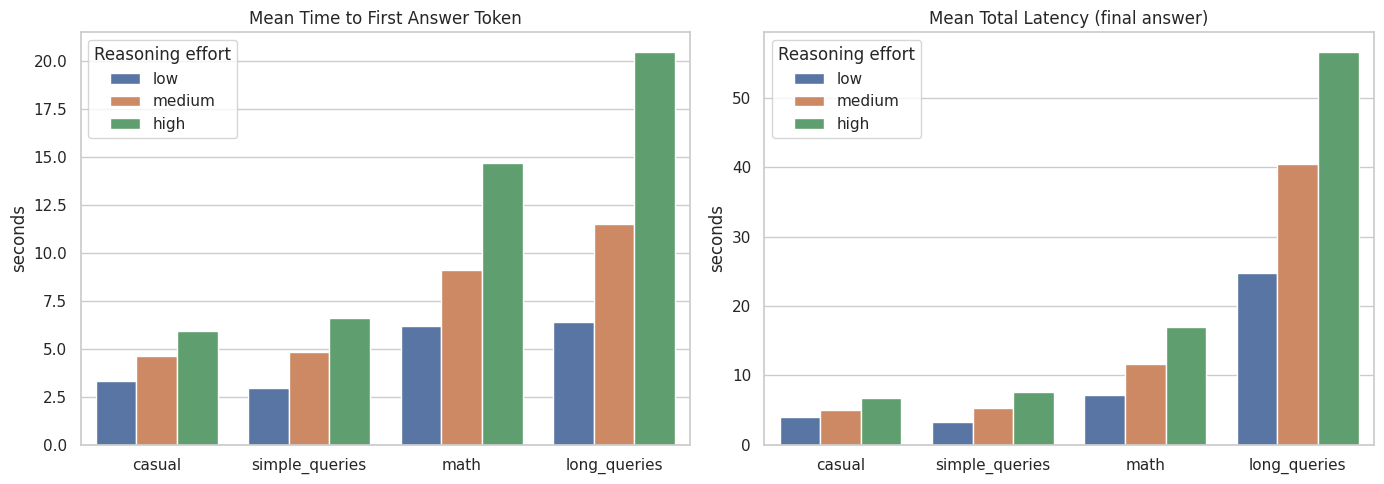

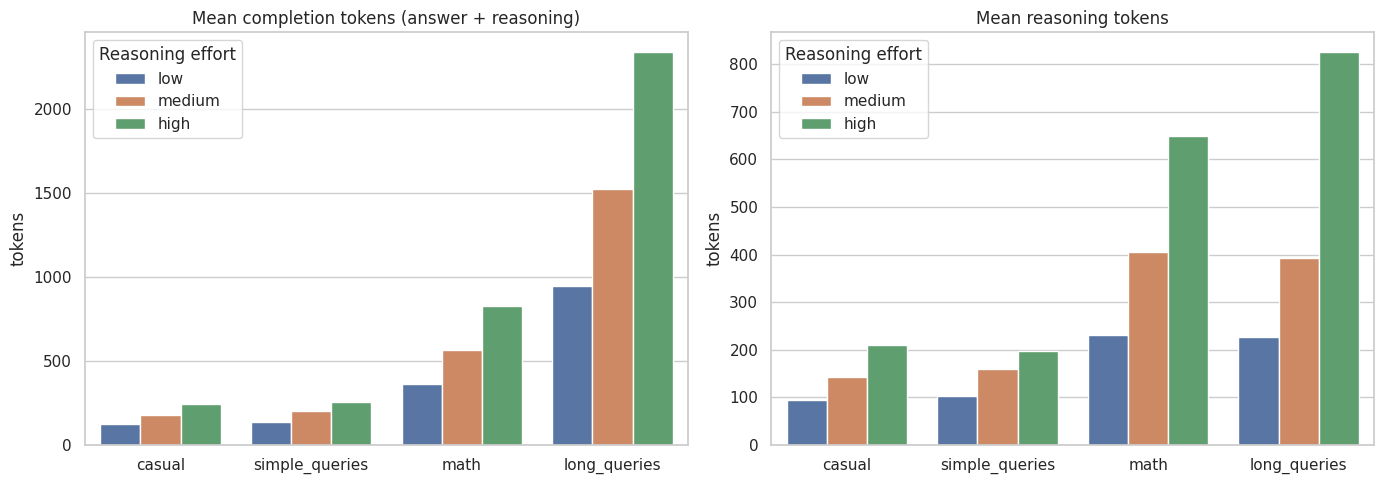

In [13]:
#@title Plot Results
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid")
THEME_ORDER = ["casual", "simple_queries", "math", "long_queries"]
EFFORT_ORDER = ["low", "medium", "high"]

# Average latency
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, title in [
    (axes[0], "ttfat_s", "Mean Time to First Answer Token"),
    (axes[1], "total_latency_s", "Mean Total Latency (final answer)"),
]:
    sns.barplot(data=df, x="theme", y=col, hue="effort",
                order=THEME_ORDER, hue_order=EFFORT_ORDER,
                errorbar=None, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("seconds")
    ax.legend(title="Reasoning effort")
plt.tight_layout()
plt.show()

# Average token usage
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x="theme", y="completion_tokens", hue="effort",
            order=THEME_ORDER, hue_order=EFFORT_ORDER,
            errorbar=None, ax=axes[0])
axes[0].set_title("Mean completion tokens (answer + reasoning)")
sns.barplot(data=df, x="theme", y="reasoning_tokens", hue="effort",
            order=THEME_ORDER, hue_order=EFFORT_ORDER,
            errorbar=None, ax=axes[1])
axes[1].set_title("Mean reasoning tokens")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("tokens")
    ax.legend(title="Reasoning effort")
plt.tight_layout()
plt.show()

## How the modes compare

Instead of eyeballing the raw means, we compute how many times more each effort level costs: verbosity (completion and reasoning tokens) and latency (time to first token and total) expressed as multipliers relative to `low`, plus the step-over-step ratio of `high` vs `medium`.


In [14]:
#@title Effort Multipliers
import pandas as pd

EFFORT_ORDER = ["low", "medium", "high"]
METRICS = [
    ("total_latency_s", "total latency (s)"),
    ("ttfat_s", "time to first answer token (s)"),
    ("completion_tokens", "completion tokens (answer + reasoning)"),
    ("reasoning_tokens", "reasoning tokens"),
    ("answer_tokens", "answer tokens"),
]


def ratio(a, b):
    """a expressed as a multiple of b, guarding against a zero baseline."""
    return a / b if b else float("nan")

overall_means = (
    df.groupby("effort")[[c for c, _ in METRICS]].mean().reindex(EFFORT_ORDER)
)

print("How the effort levels compare (averaged over all 4 themes and runs):")
for col, label in METRICS:
    m = overall_means[col]
    med_vs_low = ratio(m["medium"], m["low"])
    high_vs_low = ratio(m["high"], m["low"])
    high_vs_med = ratio(m["high"], m["medium"])
    if "tokens" in col:
        print(f"- {label}: medium is {med_vs_low:.2f}x as verbose as low; "
              f"high is {high_vs_low:.2f}x as verbose as low "
              f"({high_vs_med:.2f}x as verbose as medium)")
    else:
        print(f"- {label}: medium takes {med_vs_low:.2f}x as long as low; "
              f"high takes {high_vs_low:.2f}x as long as low "
              f"({high_vs_med:.2f}x medium)")

How the effort levels compare (averaged over all 4 themes and runs):
- total latency (s): medium takes 1.59x as long as low; high takes 2.25x as long as low (1.41x medium)
- time to first answer token (s): medium takes 1.59x as long as low; high takes 2.53x as long as low (1.59x medium)
- completion tokens (answer + reasoning): medium is 1.58x as verbose as low; high is 2.35x as verbose as low (1.49x as verbose as medium)
- reasoning tokens: medium is 1.69x as verbose as low; high is 2.89x as verbose as low (1.71x as verbose as medium)
- answer tokens: medium is 1.51x as verbose as low; high is 1.97x as verbose as low (1.31x as verbose as medium)


Let's plot how `medium` and `high` compare against `low` as a heatmap of the mean per effort level, with each metric scaled so that low = 1.0.

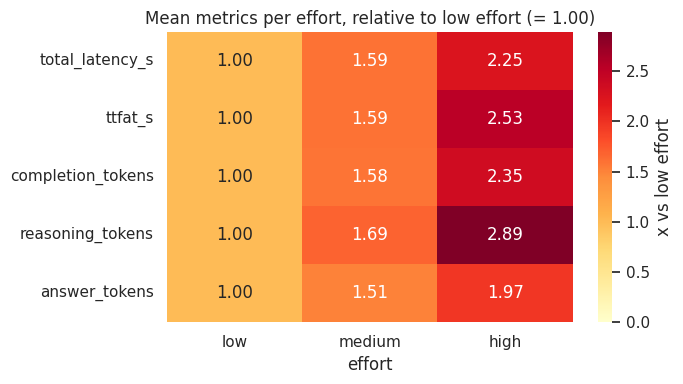

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

baseline = overall_means.loc["low"].replace(0, float("nan"))
rel = overall_means.div(baseline).T.reindex(columns=EFFORT_ORDER)

plt.figure(figsize=(7, 4))
sns.heatmap(
    rel,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0,
    cbar_kws={"label": "x vs low effort"},
)
plt.title("Mean metrics per effort, relative to low effort (= 1.00)")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## What did we learn?

**Reasoning considerably improves performance**, but it comes **with higher costs and latency**. The ability to select an effort level gives developers and users flexibility in how they balance performance, cost, and latency for their use case. Not all tasks require a high level of reasoning, so selecting the right reasoning effort is essential.

When using Mistral Large 4, most tasks will be fine with `low` reasoning effort, and you may increase it if needed:

* `medium`: More verbose than low, but still compact and optimized
* `high`: Very verbose, sacrificing latency for SOTA accuracy.